# Riesgo agroclimático por predio — Repelón (v2.1)

Riesgo = Amenaza x Vulnerabilidad
- Vulnerabilidad (V): estado de la vegetación del predio (Sentinel-2: NDVI, NDMI, SAVI)
- Amenaza (A): déficit de lluvia frente a lo normal (NASA GPM IMERG)

Secciones 0 a 7: riesgo por predio (v2, ya corrida). Secciones 8 a 11 (nuevas, aún sin probar en Earth Engine): calendario mensual, predios dentro o fuera del distrito de riego y candidatos para el ejemplo, NDVI mensual del predio de ejemplo y exportación para la demo.

IMPORTANTE: este notebook NO está validado todavía. Ver sección 7.

## 0. Configuración (aquí se cambian los parámetros; el resto no se toca)

In [1]:
PROJECT_ID = 'agro-513620'
RUTA_BASE = '/content/drive/MyDrive/Agro'
RUTA_PREDIOS = f'{RUTA_BASE}/repelon_predios_rurales.gpkg'

# Fecha final del análisis. None = hoy. Para reproducir resultados escribe 'AAAA-MM-DD'.
FECHA_FIN = None
VENTANA_DIAS = 60          # días hacia atrás que se analizan
NUBOSIDAD_MAX = 30         # % máximo de nubes por escena Sentinel-2
ESCALA_S2 = 10             # metros por píxel al extraer índices (10 m = más predios con dato)
ESCALA_GPM = 11132         # metros (resolución nativa de GPM, ~0.1 grado)
ANIOS_CLIMA = 10           # años anteriores usados para calcular la lluvia "normal"
TAMANO_LOTE = 500          # predios por consulta a Earth Engine

# Pesos de la vulnerabilidad (deben sumar 1)
PESOS_V = {'NDVI': 0.4, 'NDMI': 0.4, 'SAVI': 0.2}

# Umbrales (crítico, sano). SON SUPUESTOS INICIALES: hay que calibrarlos con datos locales.
# Si el índice vale <= crítico -> estrés 1. Si vale >= sano -> estrés 0. Entre ambos, lineal.
UMBRALES = {
    'NDVI': (0.2, 0.7),
    'NDMI': (-0.1, 0.3),
    'SAVI': (0.05, 0.5),
}

PESO_AMENAZA = 0.5         # Riesgo = PESO_AMENAZA * A + (1 - PESO_AMENAZA) * V

## 1. Librerías, autenticación y Drive

In [2]:
import warnings
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import ee
import geemap
from google.colab import drive

warnings.filterwarnings('ignore', category=UserWarning)

try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=PROJECT_ID)
print('✅ Conectado a Earth Engine')

drive.mount('/content/drive')
print('✅ Drive montado')

✅ Conectado a Earth Engine
Mounted at /content/drive
✅ Drive montado


## 2. Carga y limpieza de predios (búfer adaptativo)

In [3]:
gdf = gpd.read_file(RUTA_PREDIOS)
if gdf.crs != 'EPSG:32618':
    gdf = gdf.to_crs('EPSG:32618')   # UTM 18N: unidades en metros

gdf = gdf[gdf.geometry.notnull() & ~gdf.geometry.is_empty].copy()
gdf['geometry'] = gdf['geometry'].buffer(0)
print(f'Predios originales: {len(gdf)}')


def buffer_adaptativo(geom):
    """Recorta el borde para evitar píxeles mezclados con caminos/vecinos."""
    area = geom.area
    if area > 1000:
        return geom.buffer(-2)
    elif area > 300:
        return geom.buffer(-1)
    return geom   # predios pequeños: no se recortan para que no desaparezcan


gdf['geometry'] = gdf['geometry'].apply(buffer_adaptativo)
gdf = gdf[gdf.geometry.notnull() & ~gdf.geometry.is_empty].copy()

# La llave CODIGO debe ser texto limpio y única (con ella se cruzan todos los datos)
gdf['CODIGO'] = gdf['CODIGO'].astype(str).str.strip()
duplicados = gdf['CODIGO'].duplicated().sum()
if duplicados:
    print(f'⚠️ Hay {duplicados} CODIGO repetidos. Revisa antes de confiar en los cruces.')
gdf = gdf.reset_index(drop=True)
print(f'Predios listos: {len(gdf)}')

gdf.to_file(f'{RUTA_BASE}/repelon_predios_procesados.gpkg', driver='GPKG')

Predios originales: 1857
⚠️ Hay 9 CODIGO repetidos. Revisa antes de confiar en los cruces.
Predios listos: 1857


## 3. Fechas y función auxiliar de extracción a Earth Engine

In [4]:
FIN = pd.Timestamp(FECHA_FIN) if FECHA_FIN else pd.Timestamp.now().normalize()
INICIO = FIN - pd.Timedelta(days=VENTANA_DIAS)


def f(fecha):
    return fecha.strftime('%Y-%m-%d')


print(f'Ventana Sentinel-2: {f(INICIO)} a {f(FIN)}')

# Rectángulo que cubre todos los predios (en lat/lon), usado para filtrar imágenes
x0, y0, x1, y1 = gdf.to_crs(4326).total_bounds
region = ee.Geometry.Rectangle([float(x0), float(y0), float(x1), float(y1)])


def extraer_por_lotes(imagen, escala):
    """Promedia 'imagen' dentro de cada predio. Devuelve DataFrame con CODIGO + valores."""
    base = gdf[['CODIGO', 'geometry']]
    resultados = []
    for i in range(0, len(base), TAMANO_LOTE):
        lote = base.iloc[i:i + TAMANO_LOTE].to_crs(4326)   # Earth Engine usa lat/lon
        fc = geemap.geopandas_to_ee(lote)
        salida = imagen.reduceRegions(
            collection=fc, reducer=ee.Reducer.mean(), scale=escala, tileScale=4
        )
        info = salida.getInfo()
        resultados.append(pd.DataFrame([x['properties'] for x in info['features']]))
        print(f'  lote {i // TAMANO_LOTE + 1} de {-(-len(base) // TAMANO_LOTE)} listo')
    df = pd.concat(resultados, ignore_index=True)
    df['CODIGO'] = df['CODIGO'].astype(str).str.strip()
    return df.drop_duplicates('CODIGO')

Ventana Sentinel-2: 2026-09-16 a 2026-11-15


## 4. Vulnerabilidad (Sentinel-2)

In [5]:
def enmascarar_s2(img):
    """Quita nubes, sombras y píxeles dudosos usando la banda SCL (4=vegetación, 5=suelo)."""
    scl = img.select('SCL')
    return img.updateMask(scl.eq(4).Or(scl.eq(5)))


s2_col = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(region)
    .filterDate(f(INICIO), f(FIN))
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', NUBOSIDAD_MAX))
)
n_escenas = s2_col.size().getInfo()
print(f'Escenas Sentinel-2 disponibles: {n_escenas}')
assert n_escenas > 0, 'No hay escenas en la ventana: amplía VENTANA_DIAS o NUBOSIDAD_MAX'

# Mediana de las escenas ya enmascaradas; se divide entre 10000 para pasar a reflectancia (0-1)
s2 = s2_col.map(enmascarar_s2).select(['B4', 'B8', 'B11']).median().divide(10000)

nir, red = s2.select('B8'), s2.select('B4')
ndvi = s2.normalizedDifference(['B8', 'B4']).rename('NDVI')
ndmi = s2.normalizedDifference(['B8', 'B11']).rename('NDMI')
savi = nir.subtract(red).divide(nir.add(red).add(0.5)).multiply(1.5).rename('SAVI')
indices = ee.Image.cat([ndvi, ndmi, savi])

print('Extrayendo índices por predio...')
df_s2 = extraer_por_lotes(indices, ESCALA_S2)
df_s2.to_csv(f'{RUTA_BASE}/repel_indices_s2.csv', index=False)

for col in ['NDVI', 'NDMI', 'SAVI']:
    if col not in df_s2.columns:
        df_s2[col] = float('nan')

gdf = gdf.drop(columns=['NDVI', 'NDMI', 'SAVI'], errors='ignore')
gdf = gdf.merge(df_s2[['CODIGO', 'NDVI', 'NDMI', 'SAVI']], on='CODIGO', how='left')
sin_dato = gdf['NDVI'].isna().sum()
print(f'Predios sin dato Sentinel-2: {sin_dato} de {len(gdf)} ({100 * sin_dato / len(gdf):.1f}%)')


def estres(serie, critico, sano):
    """0 = sano, 1 = crítico. Lineal entre los dos umbrales."""
    return ((sano - serie) / (sano - critico)).clip(0, 1)


gdf['V_Vulnerability'] = sum(
    PESOS_V[k] * estres(gdf[k], *UMBRALES[k]) for k in PESOS_V
)   # si falta un índice, V queda vacío (NaN): no se inventa el dato

print('\n--- TOP 10 PREDIOS CON MAYOR VULNERABILIDAD ---')
print(
    gdf[['CODIGO', 'NDVI', 'NDMI', 'SAVI', 'V_Vulnerability']]
    .sort_values('V_Vulnerability', ascending=False)
    .head(10)
)

Escenas Sentinel-2 disponibles: 5
Extrayendo índices por predio...
  lote 1 de 4 listo
  lote 2 de 4 listo
  lote 3 de 4 listo
  lote 4 de 4 listo
Predios sin dato Sentinel-2: 0 de 1857 (0.0%)

--- TOP 10 PREDIOS CON MAYOR VULNERABILIDAD ---
                              CODIGO      NDVI      NDMI      SAVI  \
700   086060001000000010859000000000  0.048199 -0.101343  0.038754   
49    086060001000000010975000000000  0.041338 -0.115502  0.032997   
92    086060001000000010974000000000  0.033775 -0.112421  0.026953   
824   086060001000000010955000000000  0.033418 -0.111801  0.026236   
482   086060001000000010979000000000  0.032023 -0.118519  0.025160   
1706  086060001000000010977000000000  0.053725 -0.117102  0.041826   
196   086060001000000010976000000000  0.045010 -0.117259  0.035603   
336   086060001000000010978000000000  0.036958 -0.125406  0.028827   
184   086060001000000010936000000000  0.058950 -0.102060  0.046606   
186   086060001000000010973000000000  0.034393 -0.112255  

## 5. Amenaza (NASA GPM IMERG): lluvia de la ventana frente a lo normal

In [6]:
IMERG = 'NASA/GPM_L3/IMERG_V07'

# 5.1 GPM tiene retraso de publicación: la ventana no puede terminar después del último dato
ultimo_ms = (
    ee.ImageCollection(IMERG).sort('system:time_start', False)
    .first().get('system:time_start').getInfo()
)
ultimo = pd.to_datetime(ultimo_ms, unit='ms').normalize()
FIN_GPM = min(FIN, ultimo)
INICIO_GPM = FIN_GPM - pd.Timedelta(days=VENTANA_DIAS)
print(f'Último dato GPM disponible: {f(ultimo)}')
print(f'Ventana GPM usada: {f(INICIO_GPM)} a {f(FIN_GPM)}')


def lluvia_mm(inicio, fin):
    """Lluvia acumulada (mm). IMERG viene en mm/hora cada 30 min -> se multiplica por 0.5 h."""
    col = ee.ImageCollection(IMERG).filterDate(f(inicio), f(fin)).select('precipitation')
    return col.sum().multiply(0.5).rename('precip_mm'), col.size()


precip_actual, n_img = lluvia_mm(INICIO_GPM, FIN_GPM)
esperadas = VENTANA_DIAS * 48
cobertura = n_img.getInfo() / esperadas
print(f'Cobertura de imágenes GPM: {100 * cobertura:.0f}% de lo esperado')
if cobertura < 0.95:
    print('⚠️ Faltan imágenes: la lluvia estará subestimada y la amenaza exagerada.')

# 5.2 Lluvia "normal": misma ventana en los años anteriores, promediada sobre toda la zona
valores = []
for k in range(1, ANIOS_CLIMA + 1):
    ini_k = INICIO_GPM - pd.DateOffset(years=k)
    fin_k = FIN_GPM - pd.DateOffset(years=k)
    img_k, _ = lluvia_mm(ini_k, fin_k)
    v = img_k.reduceRegion(
        reducer=ee.Reducer.mean(), geometry=region, scale=ESCALA_GPM, maxPixels=1e9
    ).get('precip_mm').getInfo()
    if v is not None:
        valores.append(v)
    print(f'  {ini_k.year}: {v if v is None else round(v, 1)} mm')

assert valores, 'No se pudo calcular la lluvia normal'
LLUVIA_NORMAL = sum(valores) / len(valores)
print(f'\nLluvia normal para esta época (media de {len(valores)} años): {LLUVIA_NORMAL:.1f} mm')

# 5.3 Lluvia actual por predio y amenaza
# GPM tiene píxeles de ~11 km y los predios son más pequeños: promediar DENTRO del predio
# devuelve vacío. Por eso se toma el valor del píxel que contiene el centroide de cada predio.
cent = gdf[['CODIGO', 'geometry']].copy()
cent['geometry'] = cent.geometry.centroid
cent = cent.to_crs(4326)
filas = []
for i in range(0, len(cent), TAMANO_LOTE):
    fc = geemap.geopandas_to_ee(cent.iloc[i:i + TAMANO_LOTE])
    out = precip_actual.sampleRegions(collection=fc, properties=['CODIGO'], scale=ESCALA_GPM)
    filas += [x['properties'] for x in out.getInfo()['features']]
df_gpm = pd.DataFrame(filas)
df_gpm['CODIGO'] = df_gpm['CODIGO'].astype(str).str.strip()
df_gpm = df_gpm.drop_duplicates('CODIGO')
print(f'Predios con dato de lluvia: {len(df_gpm)} de {len(gdf)}')
df_gpm.to_csv(f'{RUTA_BASE}/repel_amenaza_gpm.csv', index=False)

gdf = gdf.drop(columns=['precip_mm', 'Precip_pct_normal', 'Amenaza_Norm'], errors='ignore')
gdf = gdf.merge(df_gpm[['CODIGO', 'precip_mm']], on='CODIGO', how='left')
gdf['Precip_pct_normal'] = 100 * gdf['precip_mm'] / LLUVIA_NORMAL
# Amenaza: 0 si llovió lo normal o más; 1 si no llovió nada
gdf['Amenaza_Norm'] = (1 - gdf['precip_mm'] / LLUVIA_NORMAL).clip(0, 1)

print(gdf[['precip_mm', 'Precip_pct_normal', 'Amenaza_Norm']].describe().round(2))
print('\nNota: GPM tiene píxeles de ~11 km, así que la amenaza varía poco entre predios.')

Último dato GPM disponible: 2026-11-14
Ventana GPM usada: 2026-09-15 a 2026-11-14
Cobertura de imágenes GPM: 100% de lo esperado
  2025: 268.1 mm
  2024: 540.7 mm
  2023: 391.3 mm
  2022: 684.1 mm
  2021: 327.7 mm
  2020: 316.4 mm
  2019: 358.0 mm
  2018: 336.4 mm
  2017: 232.2 mm
  2016: 425.4 mm

Lluvia normal para esta época (media de 10 años): 388.0 mm
Predios con dato de lluvia: 1848 de 1857
       precip_mm  Precip_pct_normal  Amenaza_Norm
count    1857.00            1857.00       1857.00
mean      374.00              96.39          0.04
std        20.36               5.25          0.05
min       304.72              78.53          0.01
25%       374.40              96.49          0.01
50%       382.86              98.67          0.01
75%       382.86              98.67          0.04
max       382.86              98.67          0.21

Nota: GPM tiene píxeles de ~11 km, así que la amenaza varía poco entre predios.


## 6. Riesgo final

In [7]:
gdf['Riesgo_Index'] = (
    PESO_AMENAZA * gdf['Amenaza_Norm'] + (1 - PESO_AMENAZA) * gdf['V_Vulnerability']
)


def clasificar_riesgo(score):
    if pd.isna(score):
        return 'Sin dato'
    if score > 0.75:
        return 'Crítico'
    if score > 0.50:
        return 'Alto'
    if score > 0.25:
        return 'Moderado'
    return 'Bajo'


gdf['Nivel_Riesgo'] = gdf['Riesgo_Index'].apply(clasificar_riesgo)

gdf.to_file(f'{RUTA_BASE}/repel_riesgo_consolidado.gpkg', driver='GPKG')   # para QGIS
pd.DataFrame(gdf.drop(columns='geometry')).to_csv(
    f'{RUTA_BASE}/repel_riesgo_consolidado.csv', index=False
)

print('✅ Riesgo calculado y guardado en Drive')
print(gdf['Nivel_Riesgo'].value_counts())

✅ Riesgo calculado y guardado en Drive
Nivel_Riesgo
Bajo        1083
Moderado     736
Alto          38
Name: count, dtype: int64


## 7. Revisión visual (NO es validación)

Estos gráficos solo comprueban que los números se ven razonables.
Validar de verdad = comparar contra datos independientes (ver GUIA_Y_BITACORA.md).

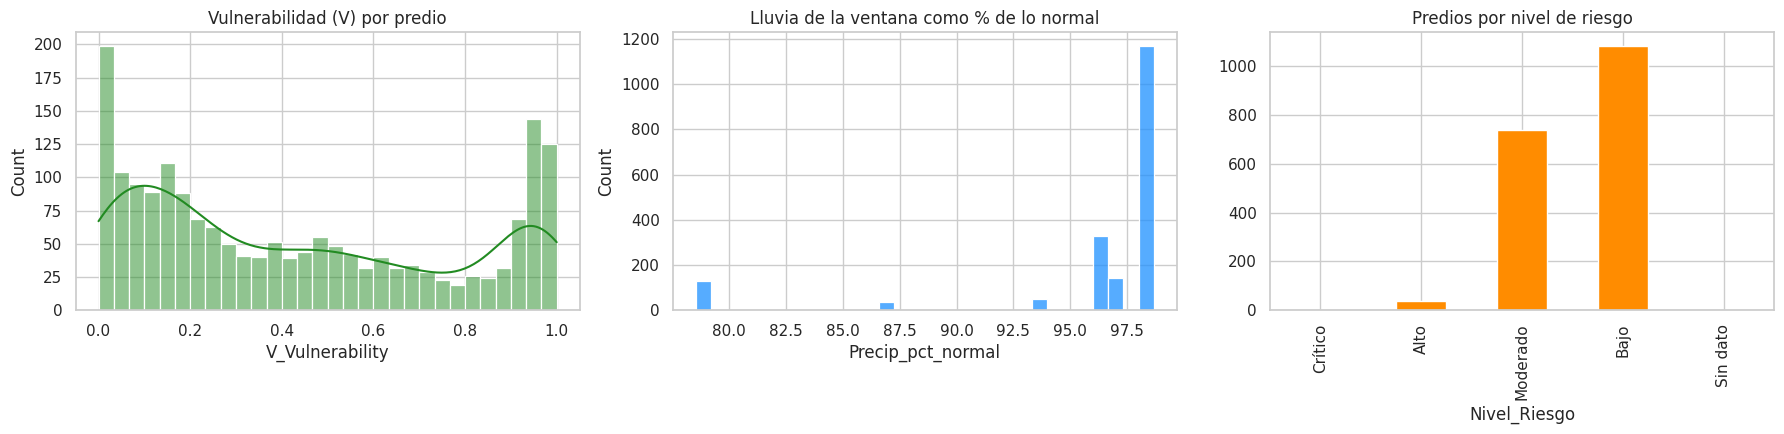

In [8]:
sns.set_theme(style='whitegrid')
fig, ejes = plt.subplots(1, 3, figsize=(18, 4.5))

sns.histplot(gdf['V_Vulnerability'].dropna(), bins=30, kde=True, ax=ejes[0], color='forestgreen')
ejes[0].set_title('Vulnerabilidad (V) por predio')

sns.histplot(gdf['Precip_pct_normal'].dropna(), bins=30, ax=ejes[1], color='dodgerblue')
ejes[1].set_title('Lluvia de la ventana como % de lo normal')

gdf['Nivel_Riesgo'].value_counts().reindex(
    ['Crítico', 'Alto', 'Moderado', 'Bajo', 'Sin dato']
).fillna(0).plot(kind='bar', ax=ejes[2], color='darkorange')
ejes[2].set_title('Predios por nivel de riesgo')

plt.tight_layout()
plt.savefig(f'{RUTA_BASE}/revision_visual.png', dpi=200, bbox_inches='tight')
plt.show()

## 8. Calendario mensual de la zona (lluvia GPM y NDVI Sentinel-2)

Para cada mes de 2021 a 2025 calcula la lluvia total (GPM) y el NDVI típico (Sentinel-2) de la zona, y luego promedia por mes del año.
Sirve para ver las temporadas secas y húmedas y los meses en que el campo suele estar sin verdor, y es la base para cruzar cada rotación con el calendario.
Es de la zona completa (un rectángulo que cubre los predios), no de un predio en particular.
Necesita haber corrido antes las secciones 0 a 5.

  año 2021 listo
  año 2022 listo
  año 2023 listo
  año 2024 listo
  año 2025 listo
Meses sin NDVI (sin escenas útiles): 2 de 60
      NDVI  lluvia_mm
mes                  
1    0.682     18.618
2    0.531     12.651
3    0.472     29.092
4    0.466    106.066
5    0.664    128.723
6    0.737    151.460
7    0.740    118.993
8    0.699    193.393
9    0.695    167.396
10   0.703    207.563
11   0.748    208.292
12   0.764     34.283


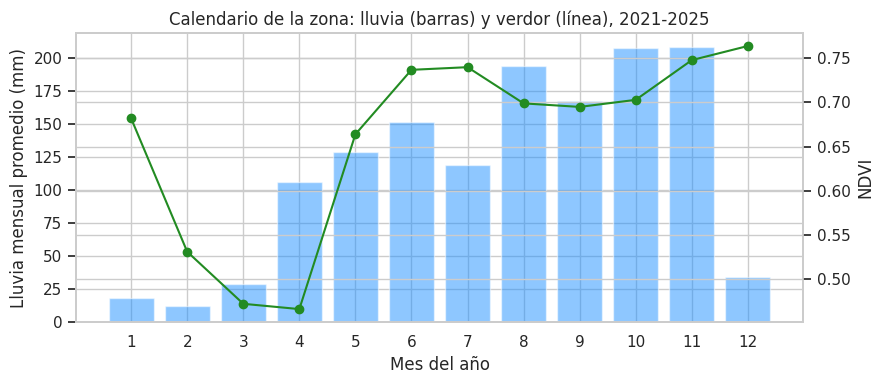

In [9]:
# ---- Parámetros del calendario ----
ANIO_INI_CAL = 2021
ANIO_FIN_CAL = 2025
ESCALA_CAL = 1000          # metros; suficiente para un promedio de zona


def con_ndvi(img):
    """NDVI de una escena Sentinel-2 ya enmascarada (sin nubes ni sombras).
    No hace falta dividir entre 10000: el NDVI es una razón y la escala se cancela."""
    m = enmascarar_s2(img)
    nir, red = m.select('B8'), m.select('B4')
    return nir.subtract(red).divide(nir.add(red)).rename('NDVI')


def fila_mes(anio, mes):
    """Lluvia (mm) y NDVI medios de la zona en un mes."""
    ini = ee.Date.fromYMD(anio, mes, 1)
    fin = ini.advance(1, 'month')
    ndvi_m = (
        ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
        .filterBounds(region).filterDate(ini, fin)
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 60))
        .map(con_ndvi).median()
    )
    lluvia_m = (
        ee.ImageCollection(IMERG).filterDate(ini, fin)
        .select('precipitation').sum().multiply(0.5).rename('lluvia_mm')
    )
    vals = lluvia_m.addBands(ndvi_m).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=region, scale=ESCALA_CAL,
        maxPixels=1e9, tileScale=4
    )
    return ee.Feature(None, vals).set('anio', anio).set('mes', mes)


filas = []
for anio in range(ANIO_INI_CAL, ANIO_FIN_CAL + 1):
    fc_anio = ee.FeatureCollection(
        ee.List.sequence(1, 12).map(lambda m: fila_mes(anio, m))
    )
    filas += [x['properties'] for x in fc_anio.getInfo()['features']]
    print(f'  año {anio} listo')

df_cal = pd.DataFrame(filas)
for col in ['NDVI', 'lluvia_mm']:
    if col not in df_cal.columns:
        df_cal[col] = float('nan')
df_cal = df_cal.sort_values(['anio', 'mes']).reset_index(drop=True)
df_cal.to_csv(f'{RUTA_BASE}/calendario_mensual_serie.csv', index=False)
print(f"Meses sin NDVI (sin escenas útiles): {df_cal['NDVI'].isna().sum()} de {len(df_cal)}")

clima = df_cal.groupby('mes')[['NDVI', 'lluvia_mm']].mean().round(3)
clima.to_csv(f'{RUTA_BASE}/calendario_mensual.csv')
print(clima)

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(clima.index, clima['lluvia_mm'], color='dodgerblue', alpha=0.5)
ax.set_xlabel('Mes del año')
ax.set_ylabel('Lluvia mensual promedio (mm)')
ax.set_xticks(range(1, 13))
ax2 = ax.twinx()
ax2.plot(clima.index, clima['NDVI'], color='forestgreen', marker='o')
ax2.set_ylabel('NDVI')
plt.title(f'Calendario de la zona: lluvia (barras) y verdor (línea), {ANIO_INI_CAL}-{ANIO_FIN_CAL}')
plt.tight_layout()
plt.savefig(f'{RUTA_BASE}/calendario_mensual.png', dpi=200, bbox_inches='tight')
plt.show()

## 9. Predios dentro o fuera del distrito de riego, y candidatos para el ejemplo

Usa el cruce hecho en QGIS entre los predios y el polígono oficial del distrito de riego de Repelón (servicio de Distritos de Adecuación de Tierras de la UPRA y la ANT). El archivo `predios_en_distrito.csv` debe estar en la carpeta Agro de Drive y traer una columna `CODIGO`.
Si el archivo no está, usa como respaldo la distancia al punto de referencia del registro de la ADR, que es solo un indicio.
Estar fuera del distrito significa que el predio probablemente NO recibe riego del distrito; no prueba que sea de secano (puede haber bombeo propio u otras fuentes).
Lista predios candidatos fuera del distrito y de más de 1 ha, con riesgo alto y con riesgo bajo, para elegir el predio de ejemplo.

In [10]:
import os
from shapely.geometry import Point

# Cruce espacial hecho en QGIS: predios que intersecan el polígono oficial del distrito de riego.
# Sube el CSV a la carpeta Agro de Drive.
RUTA_PREDIOS_DISTRITO = f'{RUTA_BASE}/predios_en_distrito_nuevo.csv'
AREA_MIN_HA = 1            # predios de más de 1 ha dan píxeles más limpios

# Punto de referencia del registro de la ADR (solo informativo): 10°29.803' N, 75°7.960' W
LAT_DISTRITO = 10 + 29.803 / 60
LON_DISTRITO = -(75 + 7.960 / 60)
punto_distrito = gpd.GeoSeries([Point(LON_DISTRITO, LAT_DISTRITO)], crs=4326).to_crs(32618).iloc[0]

gdf['area_ha'] = (gdf.geometry.area / 10000).round(2)     # área del predio ya con el búfer
gdf['dist_distrito_km'] = (gdf.geometry.centroid.distance(punto_distrito) / 1000).round(2)

if os.path.exists(RUTA_PREDIOS_DISTRITO):
    tabla_d = pd.read_csv(RUTA_PREDIOS_DISTRITO, dtype=str)
    col_cod = next((c for c in tabla_d.columns if c.strip().upper() == 'CODIGO'), None)
    assert col_cod is not None, f'El CSV no tiene una columna CODIGO. Columnas: {list(tabla_d.columns)}'
    # El export de QGIS trae también predios SIN distrito (columna 'asoc' vacía): solo cuentan los que la traen llena
    if 'asoc' in tabla_d.columns:
        tabla_d = tabla_d[tabla_d['asoc'].notna() & (tabla_d['asoc'].str.strip() != '')]
    codigos_distrito = set(tabla_d[col_cod].astype(str).str.strip())
    gdf['en_distrito'] = gdf['CODIGO'].isin(codigos_distrito)
    n_dentro = int(gdf['en_distrito'].sum())
    print(f'Predios marcados dentro del distrito: {n_dentro} de {len(gdf)} (en QGIS, regla centroide dentro: 472)')
    print(
        f"Área de esos predios: {gdf.loc[gdf['en_distrito'], 'area_ha'].sum():.0f} ha "
        '(referencia ADR: área bruta del distrito 6.825 ha, neta 3.613 ha; los predios no están todos irrigados)'
    )
    if n_dentro == 0:
        print('⚠️ Ninguno coincide: revisa que los CODIGO del CSV tengan el mismo formato que los del notebook.')
else:
    print(f'⚠️ No encontré {RUTA_PREDIOS_DISTRITO}. Uso la distancia al punto del distrito como indicio (6 km).')
    gdf['en_distrito'] = gdf['dist_distrito_km'] < 6

cand = gdf[(~gdf['en_distrito']) & (gdf['area_ha'] >= AREA_MIN_HA) & gdf['Riesgo_Index'].notna()]
cols = ['CODIGO', 'area_ha', 'dist_distrito_km', 'NDVI', 'NDMI', 'V_Vulnerability', 'Riesgo_Index', 'Nivel_Riesgo']
print(f'\nPredios candidatos fuera del distrito y de más de {AREA_MIN_HA} ha: {len(cand)}')
if len(cand) == 0:
    print('Ninguno: baja AREA_MIN_HA y vuelve a correr esta celda.')
else:
    print('\n--- Riesgo ALTO ---')
    print(cand.sort_values('Riesgo_Index', ascending=False)[cols].head(8))
    print('\n--- Riesgo BAJO ---')
    print(cand.sort_values('Riesgo_Index')[cols].head(8))

Predios marcados dentro del distrito: 472 de 1857 (en QGIS, regla centroide dentro: 472)
Área de esos predios: 5576 ha (referencia ADR: área bruta del distrito 6.825 ha, neta 3.613 ha; los predios no están todos irrigados)

Predios candidatos fuera del distrito y de más de 1 ha: 607

--- Riesgo ALTO ---
                              CODIGO  area_ha  dist_distrito_km      NDVI  \
38    086060003000000010230000000000    53.28              9.69  0.351072   
82    086060003000000010286000000000    53.00              9.62  0.398717   
1380  086060003000000010004000000000    79.97             11.87  0.412457   
1171  086060003000000010003000000000    65.36             11.99  0.423871   
292   086060003000000010012000000000    21.25              8.20  0.429453   
1571  086060003000000010217000000000    13.20             11.36  0.424099   
1510  086060003000000010002000000000    41.58             11.48  0.432333   
1432  086060003000000010010000000000    50.15              8.77  0.471169   

 

## 9b. Cobertura del suelo (ESA WorldCover): ¿el predio es cultivo, pasto, monte o construcción?

Los índices (NDVI, NDMI, SAVI) miden verdor y humedad de cualquier cobertura. Esta sección le pone a cada predio una etiqueta de qué hay dentro, usando el mapa de cobertura del suelo ESA WorldCover 2021 (10 m). **No borra predios: solo los marca**, para saber cuáles son agrícolas (cultivo o pastizal) y cuáles no (monte, construcción, suelo desnudo, agua).

In [11]:
# Cobertura del suelo por predio (ESA WorldCover 2021, 10 m)
CLASES_WC = {10: 'Arboles', 20: 'Matorral', 30: 'Pastizal', 40: 'Cultivo', 50: 'Construido',
             60: 'Suelo_desnudo', 70: 'Nieve', 80: 'Agua', 90: 'Humedal', 95: 'Manglar', 100: 'Musgo'}
UMBRAL_AGRO = 0.5     # un predio es "agropecuario" si Cultivo + Pastizal cubren al menos esta fracción

wc = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map')

filas = []
base = gdf[['CODIGO', 'geometry']]
for i in range(0, len(base), TAMANO_LOTE):
    lote = base.iloc[i:i + TAMANO_LOTE].to_crs(4326)
    fc = geemap.geopandas_to_ee(lote)
    salida = wc.reduceRegions(
        collection=fc, reducer=ee.Reducer.frequencyHistogram(), scale=10, tileScale=4
    ).getInfo()
    for x in salida['features']:
        p = x['properties']
        h = p.get('histogram') or p.get('Map') or {}
        filas.append({'CODIGO': str(p['CODIGO']).strip(), 'hist': h})
    print(f'  lote {i // TAMANO_LOTE + 1} de {-(-len(base) // TAMANO_LOTE)} listo')


def resumir(h):
    """Convierte el conteo de píxeles por clase en: clase dominante y fracción agropecuaria."""
    if not h:
        return pd.Series({'cobertura_dominante': 'Sin dato', 'pct_agropecuario': float('nan')})
    total = sum(h.values())
    por_clase = {CLASES_WC.get(int(float(k)), str(k)): v / total for k, v in h.items()}
    dominante = max(por_clase, key=por_clase.get)
    agro = por_clase.get('Cultivo', 0) + por_clase.get('Pastizal', 0)
    return pd.Series({'cobertura_dominante': dominante, 'pct_agropecuario': round(100 * agro, 1)})


df_wc = pd.DataFrame(filas).drop_duplicates('CODIGO')
df_wc = pd.concat([df_wc[['CODIGO']], df_wc['hist'].apply(resumir)], axis=1)
df_wc['uso_agropecuario'] = df_wc['pct_agropecuario'] >= 100 * UMBRAL_AGRO
df_wc.to_csv(f'{RUTA_BASE}/repel_cobertura.csv', index=False)

gdf = gdf.drop(columns=['cobertura_dominante', 'pct_agropecuario', 'uso_agropecuario'], errors='ignore')
gdf = gdf.merge(df_wc, on='CODIGO', how='left')
gdf['uso_agropecuario'] = gdf['uso_agropecuario'].fillna(False).astype(bool)

print('\n--- Cobertura dominante de los predios ---')
print(gdf['cobertura_dominante'].value_counts(dropna=False))
print(f"\nPredios agropecuarios (cultivo + pastizal >= {int(100 * UMBRAL_AGRO)} %): "
      f"{int(gdf['uso_agropecuario'].sum())} de {len(gdf)}")

print('\n--- Nivel de riesgo según uso agropecuario ---')
print(pd.crosstab(gdf['uso_agropecuario'], gdf['Nivel_Riesgo']))

print('\n--- Los 10 predios de MENOR vulnerabilidad (>= 1 ha): ¿son agrícolas? ---')
print(gdf[gdf['area_ha'] >= 1].nsmallest(10, 'V_Vulnerability')
      [['CODIGO', 'area_ha', 'V_Vulnerability', 'cobertura_dominante', 'pct_agropecuario']])
print('\n--- Los 10 predios de MAYOR vulnerabilidad (>= 1 ha) ---')
print(gdf[gdf['area_ha'] >= 1].nlargest(10, 'V_Vulnerability')
      [['CODIGO', 'area_ha', 'V_Vulnerability', 'cobertura_dominante', 'pct_agropecuario']])

  lote 1 de 4 listo
  lote 2 de 4 listo
  lote 3 de 4 listo
  lote 4 de 4 listo

--- Cobertura dominante de los predios ---
cobertura_dominante
Arboles          743
Pastizal         359
Construido       339
Suelo_desnudo    307
Cultivo           42
Matorral          38
Humedal           25
Agua               4
Name: count, dtype: int64

Predios agropecuarios (cultivo + pastizal >= 50 %): 387 de 1857

--- Nivel de riesgo según uso agropecuario ---
Nivel_Riesgo      Alto  Bajo  Moderado
uso_agropecuario                      
False               37   804       629
True                 1   279       107

--- Los 10 predios de MENOR vulnerabilidad (>= 1 ha): ¿son agrícolas? ---
                             CODIGO  area_ha  V_Vulnerability  \
7    086060002000000010190000000000    46.26              0.0   
11   086060002000000010153000000000     5.51              0.0   
39   086060001000000010124000000000   115.54              0.0   
48   086060002000000010044000000000    15.61              

## 9c. Propiedades físicas del suelo (ISRIC SoilGrids) — capa de CONTEXTO, no entra al riesgo.
Arcilla 0–5 cm, resolución 250 m, global (no es información local). SoilGrids entrega g/kg: se divide entre 10 para obtener %.
Los predios menores a un píxel de 250 m pueden quedar sin valor (cobertura parcial).

In [13]:
# --- Sección 9c: arcilla superficial (SoilGrids). Capa de contexto; NO entra al riesgo ---
# Extracción del porcentaje de arcilla superficial (0-5 cm) desde SoilGrids
soil_img = ee.Image('projects/soilgrids-isric/clay_mean').select('clay_0-5cm_mean')

filas_suelo = []
base = gdf[['CODIGO', 'geometry']]
for i in range(0, len(base), TAMANO_LOTE):
    lote = base.iloc[i:i + TAMANO_LOTE].to_crs(4326)
    fc = geemap.geopandas_to_ee(lote)
    salida = soil_img.reduceRegions(
        collection=fc, reducer=ee.Reducer.mean(), scale=250, tileScale=4
    )
    info = salida.getInfo()
    filas_suelo.append(pd.DataFrame([x['properties'] for x in info['features']]))
    print(f'  lote suelo {i // TAMANO_LOTE + 1} de {-(-len(base) // TAMANO_LOTE)} listo')

df_suelo = pd.concat(filas_suelo, ignore_index=True)
df_suelo['CODIGO'] = df_suelo['CODIGO'].astype(str).str.strip()
df_suelo = df_suelo.drop_duplicates('CODIGO')

# Integrarlo al GeoDataFrame principal
gdf = gdf.drop(columns=['soil_clay_pct'], errors='ignore')
gdf = gdf.merge(df_suelo[['CODIGO', 'mean']], on='CODIGO', how='left').rename(columns={'mean': 'soil_clay_pct'})
gdf['soil_clay_pct'] = gdf['soil_clay_pct'] / 10   # SoilGrids da g/kg -> % (la corrida original exportó g/kg sin dividir)

print(f"✅ Datos de suelo añadidos. Predios con dato de arcilla: {gdf['soil_clay_pct'].notna().sum()} de {len(gdf)}")

  lote suelo 1 de 4 listo
  lote suelo 2 de 4 listo
  lote suelo 3 de 4 listo
  lote suelo 4 de 4 listo
✅ Datos de suelo añadidos. Predios con dato de arcilla: 1189 de 1857


## 10. NDVI mensual del predio de ejemplo

Escribe abajo el CODIGO del predio elegido en la sección 9 (entre comillas) y corre la celda.
Calcula la curva de verdor mes a mes de ese predio (2021 a 2025) y marca los meses en que el NDVI baja del umbral supuesto: son los meses de posible campo desnudo o estrés.
Un NDVI bajo es solo una pista: puede ser suelo desnudo, barbecho o estrés, y el índice no los distingue.

  año 2021 listo
  año 2022 listo
  año 2023 listo
  año 2024 listo
  año 2025 listo
mes
1     0.537
2     0.370
3     0.312
4     0.261
5     0.407
6     0.595
7     0.585
8     0.615
9     0.596
10    0.636
11    0.640
12    0.681
Name: NDVI, dtype: float64


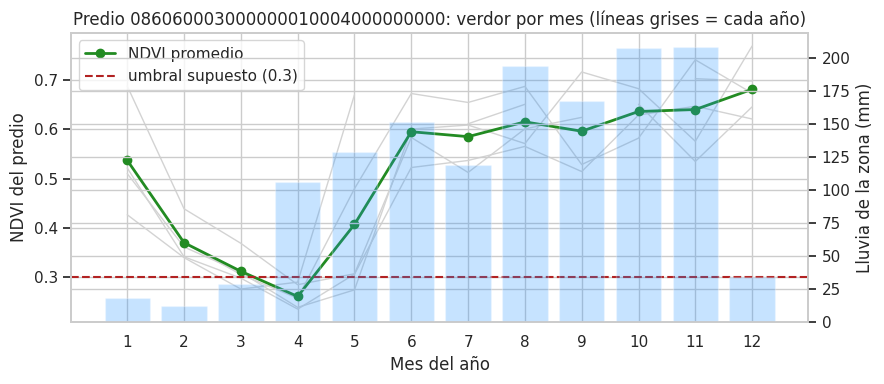

Meses con NDVI promedio por debajo de 0.3: [4]


In [14]:
CODIGO_EJEMPLO = "086060003000000010004000000000"      # escribe aquí el CODIGO elegido en la sección 9, entre comillas
NDVI_DESNUDO = 0.3         # SUPUESTO: por debajo de este NDVI mensual se marca "posible campo desnudo o estrés"

assert CODIGO_EJEMPLO is not None, 'Primero elige un CODIGO en la sección 9 y escríbelo arriba'
fila_ej = gdf[gdf['CODIGO'] == str(CODIGO_EJEMPLO).strip()]
assert len(fila_ej) > 0, 'Ese CODIGO no existe en gdf'

import json
geom = ee.Geometry(json.loads(fila_ej.to_crs(4326).iloc[[0]].to_json())['features'][0]['geometry'])


def ndvi_predio_mes(anio, mes):
    ini = ee.Date.fromYMD(anio, mes, 1)
    fin = ini.advance(1, 'month')
    img = (
        ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
        .filterBounds(geom).filterDate(ini, fin)
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 60))
        .map(con_ndvi).median()
    )
    vals = img.reduceRegion(
        reducer=ee.Reducer.mean(), geometry=geom, scale=10, maxPixels=1e9
    )
    return ee.Feature(None, vals).set('anio', anio).set('mes', mes)


filas_p = []
for anio in range(ANIO_INI_CAL, ANIO_FIN_CAL + 1):
    fc_p = ee.FeatureCollection(
        ee.List.sequence(1, 12).map(lambda m: ndvi_predio_mes(anio, m))
    )
    filas_p += [x['properties'] for x in fc_p.getInfo()['features']]
    print(f'  año {anio} listo')

df_p = pd.DataFrame(filas_p)
if 'NDVI' not in df_p.columns:
    df_p['NDVI'] = float('nan')
df_p = df_p.sort_values(['anio', 'mes']).reset_index(drop=True)
curva = df_p.groupby('mes')['NDVI'].mean().round(3)
df_p.to_csv(f'{RUTA_BASE}/ndvi_predio_ejemplo_serie.csv', index=False)
curva.to_csv(f'{RUTA_BASE}/ndvi_predio_ejemplo.csv')
print(curva)

fig, ax = plt.subplots(figsize=(9, 4))
for anio_g, g in df_p.groupby('anio'):
    ax.plot(g['mes'], g['NDVI'], color='lightgray', linewidth=1)
ax.plot(curva.index, curva.values, color='forestgreen', marker='o', linewidth=2, label='NDVI promedio')
ax.axhline(NDVI_DESNUDO, color='firebrick', linestyle='--', label=f'umbral supuesto ({NDVI_DESNUDO})')
ax.set_xticks(range(1, 13))
ax.set_xlabel('Mes del año')
ax.set_ylabel('NDVI del predio')
ax.legend(loc='upper left')
if 'clima' in globals():
    ax_ll = ax.twinx()
    ax_ll.bar(clima.index, clima['lluvia_mm'], color='dodgerblue', alpha=0.25)
    ax_ll.set_ylabel('Lluvia de la zona (mm)')
plt.title(f'Predio {CODIGO_EJEMPLO}: verdor por mes (líneas grises = cada año)')
plt.tight_layout()
plt.savefig(f'{RUTA_BASE}/ndvi_predio_ejemplo.png', dpi=200, bbox_inches='tight')
plt.show()

meses_bajos = [int(m) for m, v in curva.items() if v < NDVI_DESNUDO]
print(f'Meses con NDVI promedio por debajo de {NDVI_DESNUDO}: {meses_bajos if meses_bajos else "ninguno"}')

## 11. Exportar archivos para la página de demo

Guarda en Drive una tabla con todos los predios (riesgo, coordenadas, área, distancia al distrito) y un archivo con los parámetros y fechas usados, para poder reproducir el resultado.
Necesita haber corrido las secciones 0 a 6 y la 9.

In [15]:
import json

assert 'en_distrito' in gdf.columns, 'Corre primero la sección 9'

centros = gdf.geometry.centroid.to_crs(4326)
cols_demo = [
    'CODIGO', 'area_ha', 'en_distrito', 'dist_distrito_km', 'NDVI', 'NDMI', 'SAVI', 'V_Vulnerability',
    'precip_mm', 'Precip_pct_normal', 'Amenaza_Norm', 'Riesgo_Index', 'Nivel_Riesgo',
]
cols_demo += [c for c in ['cobertura_dominante', 'pct_agropecuario', 'uso_agropecuario', 'soil_clay_pct'] if c in gdf.columns]
exp = gdf[cols_demo].copy()
exp['baja_confianza'] = exp['area_ha'] < 0.1   # predios menores a 0,1 ha: el píxel de 10 m es grande frente a ellos
exp['lat'] = centros.y.round(5).values
exp['lon'] = centros.x.round(5).values
exp.round(4).to_csv(f'{RUTA_BASE}/predios_para_demo_{f(FIN)}.csv', index=False)

params = {
    'fecha_fin_analisis': f(FIN),
    'ventana_dias': VENTANA_DIAS,
    'ventana_gpm': [f(INICIO_GPM), f(FIN_GPM)],
    'nubosidad_max_pct': NUBOSIDAD_MAX,
    'escala_s2_m': ESCALA_S2,
    'anios_para_lluvia_normal': ANIOS_CLIMA,
    'lluvia_normal_mm': round(float(LLUVIA_NORMAL), 2),
    'pesos_V': PESOS_V,
    'umbrales_indices': {k: list(v) for k, v in UMBRALES.items()},
    'peso_amenaza': PESO_AMENAZA,
    'cortes_nivel_riesgo': {'Critico': 0.75, 'Alto': 0.50, 'Moderado': 0.25},
    'conjuntos_de_datos': {
        'sentinel2': 'COPERNICUS/S2_SR_HARMONIZED',
        'lluvia': IMERG,
        'suelo': 'ISRIC SoilGrids (clay_mean)',
    },
    'distrito_de_riego': {
        'registro': 'Registro de distritos de riego activos (ADR), archivo descargado el 14-11-2026: ASUREP, 3.613 ha, 416 familias',
        'poligono': 'Servicio de Distritos de Adecuación de Tierras (UPRA y ANT), cruzado con los predios en QGIS',
        'regla_de_asignacion': 'predios que intersecan el polígono (por verificar: puede incluir predios que solo tocan el borde)',
        'predios_dentro': int(gdf['en_distrito'].sum()),
        'punto_referencia_adr': {'lat': round(LAT_DISTRITO, 5), 'lon': round(LON_DISTRITO, 5)},
    },
    'n_predios': int(len(gdf)),
    'predios_por_nivel': {k: int(v) for k, v in gdf['Nivel_Riesgo'].value_counts().items()},
    'advertencia': 'Umbrales y pesos son supuestos iniciales sin calibrar; resultados sin validar.',
}
with open(f'{RUTA_BASE}/parametros_modelo_{f(FIN)}.json', 'w', encoding='utf-8') as fh:
    json.dump(params, fh, ensure_ascii=False, indent=2)

print(f'✅ Guardados predios_para_demo_{f(FIN)}.csv ({len(exp)} filas) y parametros_modelo_{f(FIN)}.json en Drive')

✅ Guardados predios_para_demo_2026-11-15.csv (1857 filas) y parametros_modelo_2026-11-15.json en Drive


## 12. Comprobación de la lluvia: GPM (NASA) frente a ERA5-Land (ECMWF)

Compara, mes a mes (2021 a 2025), la lluvia promedio de la zona según GPM IMERG y según ERA5-Land, que es otra fuente independiente. Si ambas se parecen, la lluvia que usa el modelo es creíble. **Corre esta sección después de las secciones 3 y 5** (usa `region` e `IMERG`).

Consultando 60 meses (puede tardar 1-2 minutos)...

Correlación mensual GPM vs ERA5-Land: 0.88  (1 = idénticas)
Promedio mensual: GPM 115 mm | ERA5-Land 134 mm

Lluvia anual (mm):
      gpm_mm  era5_mm
anio                 
2021  1092.0   1505.0
2022  1695.0   2000.0
2023  1286.0   1311.0
2024  1553.0   1679.0
2025  1248.0   1545.0

Diciembre 2024 y enero 2025:
    era5_mm  gpm_mm      mes
47     64.6    82.3  2024-12
48     35.3    52.6  2025-01


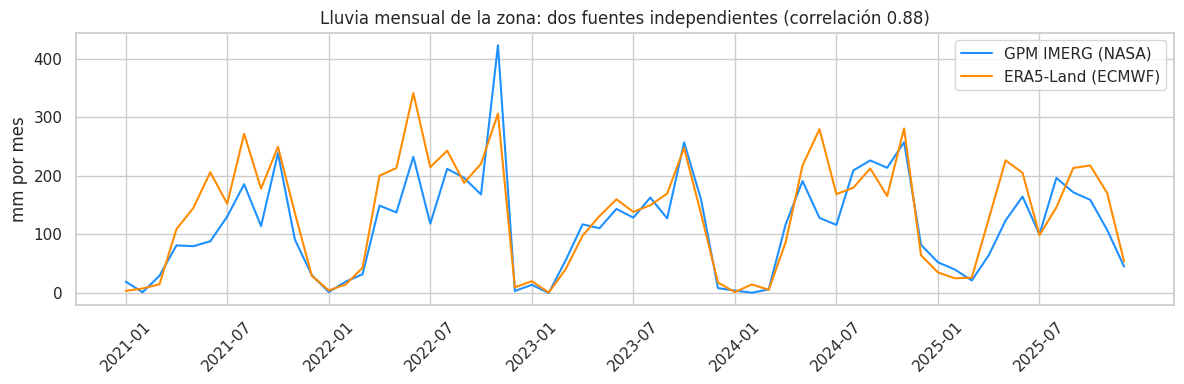

In [16]:
# Comparación mensual de lluvia: GPM IMERG vs ERA5-Land (promedio de la zona, mm por mes)
ERA5 = 'ECMWF/ERA5_LAND/MONTHLY_AGGR'
N_MESES = 60   # enero 2021 a diciembre 2025


def fila_mes(i):
    ini = ee.Date.fromYMD(2021, 1, 1).advance(ee.Number(i), 'month')
    fin = ini.advance(1, 'month')
    gpm = (ee.ImageCollection(IMERG).filterDate(ini, fin).select('precipitation')
           .sum().multiply(0.5).rename('gpm_mm'))
    era = (ee.ImageCollection(ERA5).filterDate(ini, fin).first()
           .select('total_precipitation_sum').multiply(1000).rename('era5_mm'))   # metros -> mm
    valores = gpm.addBands(era).reduceRegion(
        reducer=ee.Reducer.mean(), geometry=region, scale=ESCALA_GPM, maxPixels=1e9)
    return ee.Feature(None, valores.set('mes', ini.format('YYYY-MM')))


print('Consultando 60 meses (puede tardar 1-2 minutos)...')
info = ee.FeatureCollection(ee.List.sequence(0, N_MESES - 1).map(fila_mes)).getInfo()
cmp_ll = pd.DataFrame([x['properties'] for x in info['features']]).sort_values('mes').reset_index(drop=True)
cmp_ll.to_csv(f'{RUTA_BASE}/comparacion_lluvia_gpm_era5.csv', index=False)

corr = cmp_ll['gpm_mm'].corr(cmp_ll['era5_mm'])
anual = cmp_ll.assign(anio=cmp_ll['mes'].str[:4]).groupby('anio')[['gpm_mm', 'era5_mm']].sum().round(0)
print(f'\nCorrelación mensual GPM vs ERA5-Land: {corr:.2f}  (1 = idénticas)')
print(f"Promedio mensual: GPM {cmp_ll['gpm_mm'].mean():.0f} mm | ERA5-Land {cmp_ll['era5_mm'].mean():.0f} mm")
print('\nLluvia anual (mm):')
print(anual)

# Los dos meses de dic-2024 y ene-2025: ¿también ERA5 ve el evento?
print('\nDiciembre 2024 y enero 2025:')
print(cmp_ll[cmp_ll['mes'].isin(['2024-12', '2025-01'])].round(1))

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(cmp_ll['mes'], cmp_ll['gpm_mm'], label='GPM IMERG (NASA)', color='dodgerblue')
ax.plot(cmp_ll['mes'], cmp_ll['era5_mm'], label='ERA5-Land (ECMWF)', color='darkorange')
ax.set_xticks(range(0, N_MESES, 6))
ax.set_xticklabels(cmp_ll['mes'][::6], rotation=45)
ax.set_ylabel('mm por mes')
ax.set_title(f'Lluvia mensual de la zona: dos fuentes independientes (correlación {corr:.2f})')
ax.legend()
plt.tight_layout()
plt.savefig(f'{RUTA_BASE}/comparacion_lluvia_gpm_era5.png', dpi=200, bbox_inches='tight')
plt.show()